In [1]:
from dotenv import load_dotenv
load_dotenv()

True

In [2]:
import sys
sys.path.append('./blog-generator-agent') #import like this cuz python not support import with hypen
from langgraph.types import interrupt , Command
from graph import build_blog_graph

graph = build_blog_graph()

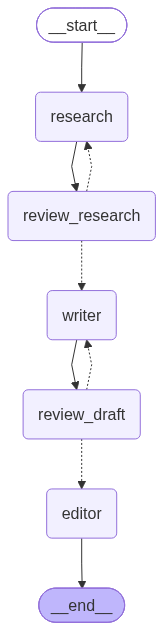

In [3]:
from IPython.display import Image
display(Image(graph.get_graph().draw_mermaid_png()))

In [4]:
config={"configurable":{"thread_id":"1"}} #help graph to remember the previous chat

In [5]:
state = graph.invoke({
    "topic":"What is MCP(model context protocol) ? A developer's guide for 2026",
    "audience":"ai and agentic ai developer"
},config=config)

In [6]:
snap = graph.get_state(config)

In [7]:
interrupt_payload = snap.interrupts[0].value #thiss is payload till interuupt node
interrupt_payload

{'stage': 'researcher_review',
 'research': '**Research Outline – “What is MCP (Model Context Protocol)? A Developer’s Guide for 2026”**  \n*Target audience: AI & agentic‑AI developers*\n\n---\n\n### 1.  What MCP Is & Why It Matters  \n- **Definition & core purpose** – standardized way to share context between LLMs, retrieval systems, and external APIs.  \n- **Key benefit** – reduces hallucinations & improves multi‑model coordination.  \n- **Hook** – “MCP: the missing glue that lets your agents talk to each other without a single line of custom code.”\n\n### 2.  Evolution of Context Management (2015‑2026)  \n- **Early approaches** – prompt‑engineering, chain‑of‑thought, retrieval‑augmented generation.  \n- **Limitations** – brittle, hard to scale, version‑conflict issues.  \n- **Stats** – 73\u202f% of enterprise LLM deployments report “context drift” problems (source: 2025 Gartner AI Ops survey).  \n- **Hook** – “See how MCP solved the 73\u202f% problem that plagued the industry.”\n\n#

In [8]:
print(interrupt_payload.get('stage'))

researcher_review


In [9]:
print("Reseach Outline for Human review:", interrupt_payload.get('research'))

Reseach Outline for Human review: **Research Outline – “What is MCP (Model Context Protocol)? A Developer’s Guide for 2026”**  
*Target audience: AI & agentic‑AI developers*

---

### 1.  What MCP Is & Why It Matters  
- **Definition & core purpose** – standardized way to share context between LLMs, retrieval systems, and external APIs.  
- **Key benefit** – reduces hallucinations & improves multi‑model coordination.  
- **Hook** – “MCP: the missing glue that lets your agents talk to each other without a single line of custom code.”

### 2.  Evolution of Context Management (2015‑2026)  
- **Early approaches** – prompt‑engineering, chain‑of‑thought, retrieval‑augmented generation.  
- **Limitations** – brittle, hard to scale, version‑conflict issues.  
- **Stats** – 73 % of enterprise LLM deployments report “context drift” problems (source: 2025 Gartner AI Ops survey).  
- **Hook** – “See how MCP solved the 73 % problem that plagued the industry.”

### 3.  MCP Architecture & Core Compon

In [10]:
#give your feedback
state = graph.invoke(Command(resume={"action":"approve" , "feedback":""}), config=config) #no feedback

In [11]:
snap = graph.get_state(config)
interrupt_payload = snap.interrupts[0].value
print(interrupt_payload.get("stage")) #reached at next human inetgruupt node stage

draft_review


In [12]:
print(interrupt_payload.get('research')) #complete blog that writer writes

# MCP (Model Context Protocol): The Missing Glue for Agentic AI in 2026

> **Hook** – *“MCP: the missing glue that lets your agents talk to each other without a single line of custom code.”*  
> If you’ve ever wrestled with context drift, hallucinations, or custom integration layers, you’re in the right place.

---

## 1. What MCP Is & Why It Matters

MCP (Model Context Protocol) is a **standardized, version‑controlled interface** that lets large language models, retrieval systems, and external APIs share and consume context as if it were a first‑class data type. Think of it as a contract that guarantees every participant in your agent ecosystem speaks the same language—no more ad‑hoc prompt engineering, no more brittle “copy‑paste” context blobs.

### Core Benefits

| Benefit | Why It Matters |
|---------|----------------|
| **Reduced Hallucinations** | Context is explicit, versioned, and auditable. |
| **Multi‑Model Coordination** | Agents can subscribe to context events and react in

In [13]:
#give your feedback
state = graph.invoke(Command(resume={"action":"approve" , "feedback":""}), config=config) #no feedback

In [14]:
print("FINAL PUBLISHED BLOG")
print(state['final_blog'])

FINAL PUBLISHED BLOG
# MCP (Model Context Protocol): The Missing Glue for Agentic AI in 2026

> **Hook** – *“MCP is the missing glue that lets your agents talk to each other without a single line of custom code.”*  
> If you’ve ever struggled with context drift, hallucinations, or custom integration layers, this guide is for you.

---

## 1. What MCP Is & Why It Matters

MCP, or Model Context Protocol, is a **standardized, version‑controlled interface** that lets large language models, retrieval systems, and external APIs share and consume context as if it were a first‑class data type. Think of it as a contract that guarantees every participant in your agent ecosystem speaks the same language—no more ad‑hoc prompt engineering, no more brittle “copy‑paste” context blobs.

### Core Benefits

| Benefit | Why It Matters |
|---------|----------------|
| **Reduced Hallucinations** | Context is explicit, versioned, and auditable. |
| **Multi‑Model Coordination** | Agents can subscribe to cont

#### NEW BLOG WITH DIFFRENT FLOW AS PER HUMAN FEEDBACK

In [15]:
config={"configurable":{"thread_id":"2"}} 
state = graph.invoke({
    "topic":"How to build simple QnA chabot with Langchain and OpenAi models?",
    "audience":"ai and agentic ai developer"
},config=config)

In [16]:
#give your feedback
state = graph.invoke(Command(resume={"action":"revise" , "feedback":"Rewrite the blog title and more focus on codes"}), config=config) #no feedback

In [ ]:
state #still we are on same interuupt stage until use says approve

{'topic': 'How to build simple QnA chabot with Langchain and OpenAi models?',
 'audience': 'ai and agentic ai developer',
 'research': '**Re‑written Title**  \n*“Code‑First Guide: Building a Simple Q&A Chatbot with LangChain & OpenAI Models”*\n\n---\n\n## Research Outline\n\n| # | Key Point | Important Facts / Stats / Examples | Suggested Angle / Hook |\n|---|-----------|------------------------------------|------------------------|\n| 1 | **Environment & Dependency Setup** | • Use Python\u202f3.10+.<br>• `pip install langchain openai`.<br>• Example: `pip install langchain==0.1.0 openai==0.28.0` to lock versions. | “Start with a clean, reproducible environment—no surprises later.” |\n| 2 | **OpenAI API Key & Model Selection** | • Key stored in `.env` (`OPENAI_API_KEY`).<br>• Models: `gpt-3.5-turbo` (fast, cheap) vs `gpt-4o-mini` (higher accuracy).<br>• Cost example: 1\u202fk tokens ≈ $0.002 for gpt‑3.5‑turbo. | “Pick the right model for your budget—see the token‑cost trade‑off.” |\n| 3

In [ ]:
#give your feedback
state = graph.invoke(Command(resume={"action":"yes" , "feedback":""}), config=config) #no feedback
state 

{'topic': 'How to build simple QnA chabot with Langchain and OpenAi models?',
 'audience': 'ai and agentic ai developer',
 'research': '**Re‑written Title**  \n*“Code‑First Guide: Building a Simple Q&A Chatbot with LangChain & OpenAI Models”*\n\n---\n\n## Research Outline\n\n| # | Key Point | Important Facts / Stats / Examples | Suggested Angle / Hook |\n|---|-----------|------------------------------------|------------------------|\n| 1 | **Environment & Dependency Setup** | • Use Python\u202f3.10+.<br>• `pip install langchain openai`.<br>• Example: `pip install langchain==0.1.0 openai==0.28.0` to lock versions. | “Start with a clean, reproducible environment—no surprises later.” |\n| 2 | **OpenAI API Key & Model Selection** | • Key stored in `.env` (`OPENAI_API_KEY`).<br>• Models: `gpt-3.5-turbo` (fast, cheap) vs `gpt-4o-mini` (higher accuracy).<br>• Cost example: 1\u202fk tokens ≈ $0.002 for gpt‑3.5‑turbo. | “Pick the right model for your budget—see the token‑cost trade‑off.” |\n| 3

In [19]:
#give your feedback
state = graph.invoke(Command(resume={"action":"yes" , "feedback":""}), config=config) #no feedback
state 

{'topic': 'How to build simple QnA chabot with Langchain and OpenAi models?',
 'audience': 'ai and agentic ai developer',
 'research': '**Re‑written Title**  \n*“Code‑First Guide: Building a Simple Q&A Chatbot with LangChain & OpenAI Models”*\n\n---\n\n## Research Outline\n\n| # | Key Point | Important Facts / Stats / Examples | Suggested Angle / Hook |\n|---|-----------|------------------------------------|------------------------|\n| 1 | **Environment & Dependency Setup** | • Use Python\u202f3.10+.<br>• `pip install langchain openai`.<br>• Example: `pip install langchain==0.1.0 openai==0.28.0` to lock versions. | “Start with a clean, reproducible environment—no surprises later.” |\n| 2 | **OpenAI API Key & Model Selection** | • Key stored in `.env` (`OPENAI_API_KEY`).<br>• Models: `gpt-3.5-turbo` (fast, cheap) vs `gpt-4o-mini` (higher accuracy).<br>• Cost example: 1\u202fk tokens ≈ $0.002 for gpt‑3.5‑turbo. | “Pick the right model for your budget—see the token‑cost trade‑off.” |\n| 3